# Step 6: Prioritize and annotate TFx-associated regional fragmentation bins

## Goal

Build a master evidence table for the **339 sample-centered tumor-fraction-associated regional fragmentation bins** identified in Step 3, prioritize them using multiple evidence layers, and annotate biologically relevant candidate regions.

This step integrates statistical evidence, chromosome-arm/cytoband enrichment, GENCODE feature overlap, and curated cancer-gene annotation.

## Inputs used in this step

* **Step 3 bin-level model results**
  Tumor-fraction coefficient, p-value, and FDR/q-value from the sample-centered regional fragmentation model.

* **Step 4 significant-bin BED files**
  Direction-specific significant bins:

  * Positive TFx-associated bins: bins where regional short/long fragmentation signal increases with tumor fraction.
  * Negative TFx-associated bins: bins where regional short/long fragmentation signal decreases with tumor fraction.

* **Step 5 enrichment results**
  Direction-specific chromosome-arm and cytoband enrichment results using the 5,000 tested robust variable bins as background.

* **GENCODE annotation**
  Used to annotate whether prioritized bins overlap gene bodies, promoters, exons, CDS, UTRs, and specific gene names.

* **Curated cancer gene list**
  Used to identify prioritized bins that overlap **protein-coding curated cancer genes**.

## Evidence layers added to each bin

Each significant bin is annotated with:

* TFx coefficient, p-value, and q-value
* Direction of association: positive or negative
* Chromosome arm and cytoband
* Whether the bin overlaps a Step 2 sample-centered significant arm
* Whether the bin lies in a Step 5 direction-specific enriched chromosome arm
* Whether the bin lies in a Step 5 direction-specific enriched cytoband
* GENCODE feature-overlap flags
* Overlapping or nearest GENCODE gene names
* Protein-coding gene status
* Curated cancer-gene status
* Evidence tier and priority score

## Evidence-tier definition

* **Tier 1:** Positive TFx-associated bins located in FDR-significant positive-enriched chromosome arms.
  In this analysis, this includes positive bins on **chr1q, chr8q, and chr20q**.

* **Tier 2:** Bins supported by focal direction-specific cytoband enrichment but not assigned to Tier 1.
  This includes focal negative-bin enrichment such as **chr11q24.3**, if present after correction.

* **Tier 3:** TFx-significant bins without chromosome-arm or focal cytoband enrichment support.

## Cancer-gene annotation

Prioritized bins are further annotated against GENCODE and the curated cancer gene list to identify bins that directly overlap:

* protein-coding genes
* curated cancer genes
* protein-coding curated cancer genes

The conservative cancer-gene output focuses on **direct overlapping genes**, rather than only nearest-gene assignments.

## Important interpretation

* These are **regional fragmentation-associated bins**, not direct CNA amplification or deletion calls.
* Positive bins on chr1q, chr8q, and chr20q should be described as **tumor-fraction-associated regional fragmentation enrichment** on these arms.
* The signal should not be interpreted as proof that these chromosome arms are amplified in every sample.
* Negative bins are still biologically relevant, especially when supported by focal cytoband enrichment.
* GENCODE and cancer-gene overlap indicate genomic-location overlap only.
* Cancer-gene overlap does not mean the gene is mutated, amplified, differentially expressed, or causally driving the fragmentation signal.

## Main outputs

This step generates:

* Master evidence table for all 339 TFx-associated bins
* Evidence-tier summary
* Direction-specific chromosome-arm and cytoband summaries
* Prioritized top-bin tables
* BED files for Tier 1, Tier 2, and Tier 3 bins
* Gene-level long table for prioritized bins
* Protein-coding curated cancer-gene overlap tables
* Plots summarizing evidence tiers, candidate arms, enriched cytobands, and evidence layers

## Next step

Step 7 will build **sample-level regional fragmentation scores** from prioritized bins and test whether these scores track tumor fraction and treatment context.



In [118]:
from pathlib import Path
import re
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths and parameters

REGIONAL_MATRIX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
)

CLINICAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

RESULT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

GTF_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/"
    "gencode.v47.annotation.gtf"
)

STEP3_TABLE_DIR = RESULT_DIR / "Step3_bin_level_screen_tables"
STEP3_PLOT_DIR  = RESULT_DIR / "Step3_bin_level_screen_plots"

STEP5_TABLE_DIR = RESULT_DIR / "Step5_enrichment_analysis_tables"
STEP5_PLOT_DIR  = RESULT_DIR / "Step5_enrichment_analysis_plots"
STEP5_BED_DIR   = RESULT_DIR / "Step5_enrichment_analysis_BED"

STEP6_TABLE_DIR = RESULT_DIR / "Step6_prioritization_tables"
STEP6_PLOT_DIR  = RESULT_DIR / "Step6_prioritization_plots"
STEP6_BED_DIR   = RESULT_DIR / "Step6_prioritization_BED"

for d in [STEP6_TABLE_DIR, STEP6_PLOT_DIR, STEP6_BED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

QVALUE_THRESHOLD = 0.05
PROMOTER_UPSTREAM_BP = 2000
PROMOTER_DOWNSTREAM_BP = 500

TOP_N_PRIORITIZED_BINS = 50
TOP_N_REGIONS_TO_PLOT = 25
TOP_N_DOTPLOT_BINS = 60

CORE_TIER1_ARMS = {"chr1q", "chr8q"}
SECONDARY_TIER1_ARMS = {"chr20q"}

print("Step 6 output folders:")
print(STEP6_TABLE_DIR)
print(STEP6_PLOT_DIR)
print(STEP6_BED_DIR)

Step 6 output folders:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_plots
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_BED


In [119]:
# 1. Helper functions

def print_section(title):
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)


def read_table(path, nrows=None):
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".csv"]:
        return pd.read_csv(path, nrows=nrows)
    if suffix in [".tsv", ".txt", ".bed"]:
        return pd.read_csv(path, sep="\t", nrows=nrows)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path, nrows=nrows)

    # fallback
    try:
        return pd.read_csv(path, sep="\t", nrows=nrows)
    except Exception:
        return pd.read_csv(path, nrows=nrows)


def normalize_chrom(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    s = s.replace("CHR", "chr").replace("Chr", "chr")

    if s.startswith("chr"):
        return s

    if re.fullmatch(r"[0-9]+|X|Y|M|MT", s):
        if s == "MT":
            s = "M"
        return "chr" + s

    return s


def make_bin_id(chrom, start, end):
    return f"{normalize_chrom(chrom)}:{int(start)}-{int(end)}"


def parse_interval_string(value):
    """
    Supports:
      chr1:100-200
      chr1_100_200
      chr1-100-200
      1:100-200
    """
    if pd.isna(value):
        return None

    s = str(value).replace(",", "").strip()

    m = re.search(
        r"(chr)?([0-9]{1,2}|X|Y|M|MT)[:_\-](\d+)[:_\-](\d+)",
        s,
        flags=re.IGNORECASE,
    )
    if not m:
        return None

    chrom = m.group(2).upper()
    if chrom == "MT":
        chrom = "M"
    chrom = "chr" + chrom
    start = int(m.group(3))
    end = int(m.group(4))
    return chrom, start, end


def add_coords_and_bin_id(df):
    """
    Add standardized columns:
      chrom, start, end, bin_id

    Works if the dataframe has explicit coordinate columns or an interval-like bin column.
    """
    df = df.copy()
    lower_to_col = {c.lower(): c for c in df.columns}

    chrom_candidates = [
        "chrom", "chr", "chromosome", "seqnames", "seqname"
    ]
    start_candidates = [
        "start", "bin_start", "window_start", "chromstart", "chrom_start"
    ]
    end_candidates = [
        "end", "bin_end", "window_end", "chromend", "chrom_end", "stop"
    ]

    chrom_col = next((lower_to_col[x] for x in chrom_candidates if x in lower_to_col), None)
    start_col = next((lower_to_col[x] for x in start_candidates if x in lower_to_col), None)
    end_col = next((lower_to_col[x] for x in end_candidates if x in lower_to_col), None)

    if chrom_col and start_col and end_col:
        df["chrom"] = df[chrom_col].map(normalize_chrom)
        df["start"] = pd.to_numeric(df[start_col], errors="coerce").astype("Int64")
        df["end"] = pd.to_numeric(df[end_col], errors="coerce").astype("Int64")
        df = df.dropna(subset=["chrom", "start", "end"]).copy()
        df["start"] = df["start"].astype(int)
        df["end"] = df["end"].astype(int)
        df["bin_id"] = [
            make_bin_id(c, s, e)
            for c, s, e in zip(df["chrom"], df["start"], df["end"])
        ]
        return df

    # Try interval-like columns
    object_cols = [c for c in df.columns if df[c].dtype == "object"]
    best_col = None
    best_count = 0

    for c in object_cols:
        parsed = df[c].head(200).map(parse_interval_string)
        n = parsed.notna().sum()
        if n > best_count:
            best_col = c
            best_count = n

    if best_col is not None and best_count > 0:
        parsed_all = df[best_col].map(parse_interval_string)
        parsed_df = pd.DataFrame(
            parsed_all.tolist(),
            index=df.index,
            columns=["chrom", "start", "end"],
        )
        df = pd.concat([df, parsed_df], axis=1)
        df = df.dropna(subset=["chrom", "start", "end"]).copy()
        df["start"] = df["start"].astype(int)
        df["end"] = df["end"].astype(int)
        df["bin_id"] = [
            make_bin_id(c, s, e)
            for c, s, e in zip(df["chrom"], df["start"], df["end"])
        ]
        return df

    raise ValueError("Could not identify genomic coordinate columns or interval-like bin column.")


def read_bed(path):
    """
    Read BED with or without header.
    Returns chrom/start/end/bin_id and preserves extra columns.
    """
    path = Path(path)

    with open(path, "r") as f:
        first = f.readline().strip().split("\t")

    has_header = False
    if len(first) >= 3:
        first_lower = [x.lower() for x in first[:3]]
        if first_lower[0] in ["chrom", "chr", "chromosome"] or first_lower[1] == "start":
            has_header = True

    if has_header:
        df = pd.read_csv(path, sep="\t")
        df = add_coords_and_bin_id(df)
        return df

    df = pd.read_csv(path, sep="\t", header=None)
    base_cols = ["chrom", "start", "end"]
    extra_cols = [f"bed_extra_{i}" for i in range(df.shape[1] - 3)]
    df.columns = base_cols + extra_cols
    df = add_coords_and_bin_id(df)
    return df


def find_exact_file(filename, root=RESULT_DIR):
    hits = list(Path(root).rglob(filename))
    if len(hits) == 0:
        raise FileNotFoundError(f"Could not find: {filename} under {root}")
    if len(hits) > 1:
        print(f"Multiple matches for {filename}. Using first:")
        for h in hits:
            print("  ", h)
    return hits[0]


def find_col_by_terms(columns, include_any=None, include_all=None, exclude_any=None):
    include_any = include_any or []
    include_all = include_all or []
    exclude_any = exclude_any or []

    scored = []
    for c in columns:
        cl = c.lower()
        if include_any and not any(x in cl for x in include_any):
            continue
        if include_all and not all(x in cl for x in include_all):
            continue
        if exclude_any and any(x in cl for x in exclude_any):
            continue
        score = 0
        score += sum(x in cl for x in include_any)
        score += sum(x in cl for x in include_all) * 2
        scored.append((score, c))

    if not scored:
        return None

    scored = sorted(scored, key=lambda x: (-x[0], x[1]))
    return scored[0][1]


def choose_stat_col(columns, stat_terms, prefer_effect_terms=None):
    """
    Pick columns like TFx_coef, tumor_fraction_qvalue, etc.
    Penalizes treatment-context columns.
    """
    prefer_effect_terms = prefer_effect_terms or ["tfx", "tumor", "fraction"]

    penalty_terms = [
        "treatment", "context", "pre", "post", "on_treatment",
        "off_treatment", "active_treatment"
    ]

    scored = []
    for c in columns:
        cl = c.lower()
        if not any(s in cl for s in stat_terms):
            continue

        score = 0
        score += 5 * sum(s in cl for s in stat_terms)
        score += 3 * sum(e in cl for e in prefer_effect_terms)
        score -= 5 * sum(p in cl for p in penalty_terms)

        scored.append((score, c))

    if not scored:
        return None

    scored = sorted(scored, key=lambda x: (-x[0], x[1]))
    return scored[0][1]


def normalize_direction(x):
    if pd.isna(x):
        return np.nan
    s = str(x).lower().strip()
    if s in ["pos", "positive", "+", "1", "up"]:
        return "positive"
    if s in ["neg", "negative", "-", "-1", "down"]:
        return "negative"
    if "positive" in s or "pos" == s:
        return "positive"
    if "negative" in s or "neg" == s:
        return "negative"
    return s


def normalize_arm_label(x):
    if pd.isna(x):
        return np.nan

    s = str(x).strip()
    s = s.replace(" ", "")
    s = s.replace("CHR", "chr").replace("Chr", "chr")

    m = re.fullmatch(r"(chr)?([0-9]{1,2}|X|Y)([pq])", s, flags=re.IGNORECASE)
    if m:
        chrom = m.group(2).upper()
        arm = m.group(3).lower()
        return f"chr{chrom}{arm}"

    return s


def normalize_cytoband_label(chrom, cytoband):
    if pd.isna(cytoband):
        return np.nan

    band = str(cytoband).strip().replace(" ", "")
    band = band.replace("CHR", "chr").replace("Chr", "chr")

    if band.startswith("chr"):
        return band

    # e.g. q32.1 or p11.2
    if re.match(r"^[pq][0-9]", band):
        return f"{normalize_chrom(chrom)}{band}"

    return band


def arm_from_cytoband(cytoband):
    if pd.isna(cytoband):
        return np.nan

    s = str(cytoband).strip()
    m = re.match(r"^(chr[0-9XY]+)([pq])", s)
    if m:
        return f"{m.group(1)}{m.group(2)}"

    return np.nan


def save_plot(path):
    path = Path(path)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.savefig(path.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()


In [120]:
# 2. Load Step 4 significant-bin BED files

print_section("Loading Step 4 significant-bin BED files")

bed_all_path = find_exact_file("04_sample_centered_TFx_significant_bins_ALL.bed")
bed_pos_path = find_exact_file("04_sample_centered_TFx_significant_bins_POSITIVE.bed")
bed_neg_path = find_exact_file("04_sample_centered_TFx_significant_bins_NEGATIVE.bed")
bed_in_step2_arm_path = find_exact_file("04_sample_centered_TFx_bins_IN_step2_significant_arms.bed")
bed_not_step2_arm_path = find_exact_file("04_sample_centered_TFx_bins_NOT_in_step2_significant_arms.bed")

bins_all = read_bed(bed_all_path)
bins_pos = read_bed(bed_pos_path)
bins_neg = read_bed(bed_neg_path)
bins_in_step2 = read_bed(bed_in_step2_arm_path)

pos_ids = set(bins_pos["bin_id"])
neg_ids = set(bins_neg["bin_id"])
in_step2_ids = set(bins_in_step2["bin_id"])

master = bins_all[["chrom", "start", "end", "bin_id"]].drop_duplicates().copy()

master["direction"] = np.select(
    [
        master["bin_id"].isin(pos_ids),
        master["bin_id"].isin(neg_ids),
    ],
    [
        "positive",
        "negative",
    ],
    default=np.nan,
)

master["overlaps_step2_significant_arm"] = master["bin_id"].isin(in_step2_ids)

print("All significant bins:", master.shape[0])
print(master["direction"].value_counts(dropna=False))
print("Bins overlapping Step 2 significant arms:", master["overlaps_step2_significant_arm"].sum())

assert master.shape[0] == 339, "Expected 339 sample-centered TFx-significant bins."
assert master["direction"].eq("positive").sum() == 220, "Expected 220 positive bins."
assert master["direction"].eq("negative").sum() == 119, "Expected 119 negative bins."


Loading Step 4 significant-bin BED files
All significant bins: 339
positive    220
negative    119
Name: direction, dtype: int64
Bins overlapping Step 2 significant arms: 112


In [121]:
# 3. Load Step 3 bin-level model statistics
# This block directly uses the correct Step 3 significant-bin model output:
# 03_significant_bins_tumor_fraction_FDR05_robust_screen.csv

print_section("Loading Step 3 TFx coefficient/q-value table directly")

step3_sig_file = STEP3_TABLE_DIR / "03_significant_bins_tumor_fraction_FDR05_robust_screen.csv"

step3_tfx = pd.read_csv(step3_sig_file)

print("Step 3 significant TFx table:")
print(step3_sig_file)
print("Shape:", step3_tfx.shape)

print("\nColumns:")
print(step3_tfx.columns.tolist())

display(step3_tfx.head())

# ------------------------------------------------------------
# Keep only sample-centered model results
# ------------------------------------------------------------

print("\nMatrix type counts before filtering:")
print(step3_tfx["matrix_type"].value_counts(dropna=False))

step3_tfx["matrix_type"] = step3_tfx["matrix_type"].astype(str).str.strip()

step3_tfx = step3_tfx[
    step3_tfx["matrix_type"].eq("sample_centered")
].copy()

print("\nMatrix type counts after filtering:")
print(step3_tfx["matrix_type"].value_counts(dropna=False))

print("Rows after keeping sample_centered:", step3_tfx.shape[0])
print("Unique bins after keeping sample_centered:", step3_tfx["bin"].nunique())

# ------------------------------------------------------------
# Standardize genomic coordinates and bin_id
# ------------------------------------------------------------

step3_tfx = add_coords_and_bin_id(step3_tfx)

print("\nAfter coordinate parsing:")
display(step3_tfx[["chrom", "start", "end", "bin_id"]].head())

print(step3_tfx["matrix_type"].value_counts(dropna=False))
print("Total rows:", step3_tfx.shape[0])
print("Unique bins before filtering:", step3_tfx["bin"].nunique())

# ------------------------------------------------------------
# Exact model-stat columns from Step 3 output
# ------------------------------------------------------------

coef_col = "coef_tumor_fraction_percent"
p_col = "p_tumor_fraction_percent"
q_col = "q_tumor_fraction_percent"

required_cols = [coef_col, p_col, q_col]

missing_required = [c for c in required_cols if c not in step3_tfx.columns]

if len(missing_required) > 0:
    raise ValueError(f"Missing required Step 3 columns: {missing_required}")

print("\nUsing Step 3 columns:")
print("coef_col:", coef_col)
print("p_col:", p_col)
print("q_col:", q_col)


# ------------------------------------------------------------
# Build clean Step 3 TFx statistics table
# ------------------------------------------------------------

step3_keep = step3_tfx[["bin_id"]].copy()

step3_keep["tfx_coef"] = pd.to_numeric(
    step3_tfx[coef_col],
    errors="coerce"
)

step3_keep["tfx_pvalue"] = pd.to_numeric(
    step3_tfx[p_col],
    errors="coerce"
)

step3_keep["tfx_qvalue"] = pd.to_numeric(
    step3_tfx[q_col],
    errors="coerce"
)

step3_keep = step3_keep.drop_duplicates("bin_id")

print("\nStep 3 keep table:")
print(step3_keep.shape)
display(step3_keep.head())


# ------------------------------------------------------------
# Merge Step 3 statistics into Step 6 master table
# ------------------------------------------------------------

old_stat_cols = [
    "tfx_coef",
    "tfx_pvalue",
    "tfx_qvalue",
    "direction_from_coef",
    "abs_tfx_coef",
    "minus_log10_tfx_qvalue",
]

master = master.drop(
    columns=[c for c in old_stat_cols if c in master.columns],
    errors="ignore"
)

master = master.merge(
    step3_keep,
    on="bin_id",
    how="left"
)

master["direction_from_coef"] = np.where(
    master["tfx_coef"] > 0,
    "positive",
    np.where(master["tfx_coef"] < 0, "negative", np.nan),
)

direction_mismatch = (
    master["direction"].notna()
    & master["direction_from_coef"].notna()
    & (master["direction"] != master["direction_from_coef"])
).sum()

master["abs_tfx_coef"] = master["tfx_coef"].abs()

master["minus_log10_tfx_qvalue"] = -np.log10(
    master["tfx_qvalue"].clip(lower=1e-300)
)


# ------------------------------------------------------------
# QC checks
# ------------------------------------------------------------

print("\nStep 3 merge check:")
print("Master rows:", master.shape[0])
print("Missing tfx_coef:", master["tfx_coef"].isna().sum())
print("Missing tfx_pvalue:", master["tfx_pvalue"].isna().sum())
print("Missing tfx_qvalue:", master["tfx_qvalue"].isna().sum())
print("Direction mismatch:", direction_mismatch)

print("\nDirection from Step 4 BED:")
print(master["direction"].value_counts(dropna=False))

print("\nDirection from Step 3 coefficient:")
print(master["direction_from_coef"].value_counts(dropna=False))

if master["tfx_coef"].isna().sum() == master.shape[0]:
    raise ValueError(
        "All tfx_coef values are missing. Check bin_id matching between Step 3 and Step 4."
    )

if direction_mismatch > 0:
    print(
        "\nWARNING: Some Step 4 direction labels do not match Step 3 coefficient signs. "
        "Check whether the coefficient column is correct."
    )

display(master.head())



Loading Step 3 TFx coefficient/q-value table directly
Step 3 significant TFx table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables/03_significant_bins_tumor_fraction_FDR05_robust_screen.csv
Shape: (5337, 38)

Columns:
['bin', 'matrix_type', 'model_engine', 'n_samples', 'n_patients', 'n_pre', 'n_on', 'n_post_off', 'model_status', 'model_error', 'coef_on_vs_pre', 'p_on_vs_pre', 'coef_post_off_vs_pre', 'p_post_off_vs_pre', 'coef_tumor_fraction_percent', 'p_tumor_fraction_percent', 'wald_chi2_treatment_overall', 'p_treatment_overall', 'q_treatment_overall', 'q_tumor_fraction_percent', 'max_abs_treatment_coef_vs_pre', 'chrom', 'start', 'end', 'midpoint', 'cytoband', 'arm', 'chrom_arm', 'chrom_order', 'iqr', 'mad', 'sd', 'missing_fraction', 'max_abs', 'n_abs_gt_10', 'tumor_fraction_direction', 'on_vs_pre_direction', 'post_off_vs_pre_direction']


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
0,chr10_62000000_62100000,raw,cluster_ols,750,260,74,491,185,ok,NaN,...,10,0.140606,0.068933,0.131465,0.0,1.330409,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1,chr2_44400000_44500000,raw,cluster_ols,750,260,74,491,185,ok,NaN,...,2,0.135712,0.065399,0.121751,0.0,0.937203,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2,chr8_116100000_116200000,raw,cluster_ols,750,260,74,491,185,ok,NaN,...,8,0.136586,0.064268,0.135163,0.0,1.215251,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3,chr8_112500000_112600000,raw,cluster_ols,750,260,74,491,185,ok,NaN,...,8,0.136225,0.062544,0.132346,0.0,0.942284,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4,chr17_76000000_76100000,raw,cluster_ols,750,260,74,491,185,ok,NaN,...,17,0.136089,0.066694,0.129280,0.0,1.234548,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre



Matrix type counts before filtering:
raw                4998
sample_centered     339
Name: matrix_type, dtype: int64

Matrix type counts after filtering:
sample_centered    339
Name: matrix_type, dtype: int64
Rows after keeping sample_centered: 339
Unique bins after keeping sample_centered: 339

After coordinate parsing:


,chrom,start,end,bin_id
4998,chr8,140800000,140900000,chr8:140800000-140900000
4999,chr21,13000000,13100000,chr21:13000000-13100000
5000,chr11,128700000,128800000,chr11:128700000-128800000
5001,chr8,140700000,140800000,chr8:140700000-140800000
5002,chr1,204400000,204500000,chr1:204400000-204500000


sample_centered    339
Name: matrix_type, dtype: int64
Total rows: 339
Unique bins before filtering: 339

Using Step 3 columns:
coef_col: coef_tumor_fraction_percent
p_col: p_tumor_fraction_percent
q_col: q_tumor_fraction_percent

Step 3 keep table:
(339, 4)


,bin_id,tfx_coef,tfx_pvalue,tfx_qvalue
4998,chr8:140800000-140900000,0.001634,2.133359e-12,1.066679e-08
4999,chr21:13000000-13100000,-0.001493,2.260418e-10,5.651044e-07
5000,chr11:128700000-128800000,-0.001478,3.608351e-08,4.510438e-05
5001,chr8:140700000-140800000,0.001292,3.195005e-08,4.510438e-05
5002,chr1:204400000-204500000,0.001165,5.767690e-08,5.767690e-05



Step 3 merge check:
Master rows: 339
Missing tfx_coef: 0
Missing tfx_pvalue: 0
Missing tfx_qvalue: 0
Direction mismatch: 0

Direction from Step 4 BED:
positive    220
negative    119
Name: direction, dtype: int64

Direction from Step 3 coefficient:
positive    220
negative    119
Name: direction_from_coef, dtype: int64


,chrom,start,end,bin_id,direction,overlaps_step2_significant_arm,tfx_coef,tfx_pvalue,tfx_qvalue,direction_from_coef,abs_tfx_coef,minus_log10_tfx_qvalue
0,chr8,140800000,140900000,chr8:140800000-140900000,positive,True,0.001634,2.133359e-12,1.066679e-08,positive,0.001634,7.971966
1,chr21,13000000,13100000,chr21:13000000-13100000,negative,False,-0.001493,2.260418e-10,5.651044e-07,negative,0.001493,6.247871
2,chr8,140700000,140800000,chr8:140700000-140800000,positive,True,0.001292,3.195005e-08,4.510438e-05,positive,0.001292,4.345781
3,chr11,128700000,128800000,chr11:128700000-128800000,negative,True,-0.001478,3.608351e-08,4.510438e-05,negative,0.001478,4.345781
4,chr1,204400000,204500000,chr1:204400000-204500000,positive,False,0.001165,5.767690e-08,5.767690e-05,positive,0.001165,4.238998


In [122]:
# Step 4-8. annotation, evidence loading, tiering, and BED export

print_section("Annotation, evidence loading, and tiering")
# ------------------------------------------------------------
# Load exact Step 5 files
# ------------------------------------------------------------

arm_enrichment_file = STEP5_TABLE_DIR / "05_direction_specific_chromosome_arm_enrichment.tsv"
cytoband_full_file = STEP5_TABLE_DIR / "05_cytoband_full_label_enrichment_results.tsv"
gencode_overlap_file = STEP5_TABLE_DIR / "05_primary_bins_gencode_feature_overlap_matrix.csv"

arm_enr = pd.read_csv(arm_enrichment_file, sep="\t")
cyto_full_enr = pd.read_csv(cytoband_full_file, sep="\t")
gencode_overlap = pd.read_csv(gencode_overlap_file)

print("Arm enrichment table:", arm_enr.shape)
print("Full cytoband enrichment table:", cyto_full_enr.shape)
print("GENCODE overlap matrix:", gencode_overlap.shape)

print("\nArm enrichment columns:")
print(arm_enr.columns.tolist())

print("\nFull cytoband enrichment columns:")
print(cyto_full_enr.columns.tolist())

print("\nGENCODE overlap matrix columns:")
print(gencode_overlap.columns.tolist())


# ------------------------------------------------------------
# Merge Step 5 annotation into master by chrom/start/end
# ------------------------------------------------------------

gencode_overlap = gencode_overlap.copy()

gencode_overlap["chrom"] = gencode_overlap["chrom"].astype(str)
gencode_overlap["start"] = pd.to_numeric(
    gencode_overlap["start"], errors="coerce"
).astype(int)
gencode_overlap["end"] = pd.to_numeric(
    gencode_overlap["end"], errors="coerce"
).astype(int)

# Create full cytoband label.
# Example: chrom = chr8, cytoband = q24.3 -> chr8q24.3
gencode_overlap["cytoband_full"] = (
    gencode_overlap["chrom"].astype(str)
    + gencode_overlap["cytoband"].astype(str)
)

gencode_cols = [
    "chrom", "start", "end",
    "chrom_arm", "cytoband", "cytoband_full",
    "overlap__GENCODE_gene_body",
    "overlap__GENCODE_promoter_2000up_500down",
    "overlap__GENCODE_exon",
    "overlap__GENCODE_CDS",
    "overlap__GENCODE_UTR",
]

gencode_cols = [c for c in gencode_cols if c in gencode_overlap.columns]

# Remove old incomplete annotation columns if they already exist
cols_to_remove = [
    "chrom_arm", "cytoband", "cytoband_full",
    "overlap__GENCODE_gene_body",
    "overlap__GENCODE_promoter_2000up_500down",
    "overlap__GENCODE_exon",
    "overlap__GENCODE_CDS",
    "overlap__GENCODE_UTR",
]

for c in cols_to_remove:
    if c in master.columns:
        master = master.drop(columns=[c])

master = master.merge(
    gencode_overlap[gencode_cols],
    on=["chrom", "start", "end"],
    how="left"
)

print("\nAfter merging Step 5 GENCODE overlap matrix:")
print("Master rows:", master.shape[0])
print("Missing chrom_arm:", master["chrom_arm"].isna().sum())
print("Missing cytoband_full:", master["cytoband_full"].isna().sum())

print("\nTop chromosome arms:")
print(master["chrom_arm"].value_counts(dropna=False).head(20))

print("\nTop cytobands:")
print(master["cytoband_full"].value_counts(dropna=False).head(20))


# ------------------------------------------------------------
# Extract Step 5 enriched chromosome arms
# ------------------------------------------------------------

positive_enriched_arms = set(
    arm_enr.loc[
        arm_enr["foreground"].eq("positive")
        & arm_enr["q_value"].lt(0.05)
        & arm_enr["odds_ratio"].gt(1),
        "category"
    ]
)

negative_enriched_arms = set(
    arm_enr.loc[
        arm_enr["foreground"].eq("negative")
        & arm_enr["q_value"].lt(0.05)
        & arm_enr["odds_ratio"].gt(1),
        "category"
    ]
)

print("\nPositive enriched arms from Step 5:")
print(sorted(positive_enriched_arms))

print("\nNegative enriched arms from Step 5:")
print(sorted(negative_enriched_arms))


# ------------------------------------------------------------
# Extract Step 5 enriched full cytobands
# ------------------------------------------------------------

positive_enriched_cytobands = set(
    cyto_full_enr.loc[
        cyto_full_enr["foreground"].eq("positive")
        & cyto_full_enr["q_value"].lt(0.05)
        & cyto_full_enr["odds_ratio"].gt(1),
        "category"
    ]
)

negative_enriched_cytobands = set(
    cyto_full_enr.loc[
        cyto_full_enr["foreground"].eq("negative")
        & cyto_full_enr["q_value"].lt(0.05)
        & cyto_full_enr["odds_ratio"].gt(1),
        "category"
    ]
)

print("\nPositive enriched cytobands from Step 5:")
print(sorted(positive_enriched_cytobands))

print("\nNegative enriched cytobands from Step 5:")
print(sorted(negative_enriched_cytobands))


# ------------------------------------------------------------
# 5. Define core and secondary Tier 1 arms
# ------------------------------------------------------------

# Strong positive arm-level evidence
core_positive_arms = positive_enriched_arms

# No secondary tier now
secondary_positive_arms = set()
# ------------------------------------------------------------
# Add Step 5 evidence flags to master
# ------------------------------------------------------------

master["arm_enriched_step5_positive"] = master["chrom_arm"].isin(
    positive_enriched_arms
)

master["arm_enriched_step5_negative"] = master["chrom_arm"].isin(
    negative_enriched_arms
)

master["arm_enriched_step5_core_positive"] = master["chrom_arm"].isin(
    core_positive_arms
)

master["arm_enriched_step5_secondary_positive"] = master["chrom_arm"].isin(
    secondary_positive_arms
)

master["cytoband_enriched_step5_positive"] = master["cytoband_full"].isin(
    positive_enriched_cytobands
)

master["cytoband_enriched_step5_negative"] = master["cytoband_full"].isin(
    negative_enriched_cytobands
)

master["arm_enriched_step5_same_direction"] = np.where(
    master["direction"].eq("positive"),
    master["arm_enriched_step5_positive"],
    np.where(
        master["direction"].eq("negative"),
        master["arm_enriched_step5_negative"],
        False,
    ),
)

master["cytoband_enriched_step5_same_direction"] = np.where(
    master["direction"].eq("positive"),
    master["cytoband_enriched_step5_positive"],
    np.where(
        master["direction"].eq("negative"),
        master["cytoband_enriched_step5_negative"],
        False,
    ),
)

print("\nPositive bins in Step 5 positive-enriched arms:")
print(
    (
        master["direction"].eq("positive")
        & master["arm_enriched_step5_positive"]
    ).sum()
)

print("\nNegative bins in Step 5 negative-enriched cytobands:")
print(
    (
        master["direction"].eq("negative")
        & master["cytoband_enriched_step5_negative"]
    ).sum()
)


# ------------------------------------------------------------
# Assign evidence tiers
# ------------------------------------------------------------

def assign_evidence_tier(row):
    # Tier 1: positive TFx bins in any FDR-significant positive-enriched arm
    if (
        row["direction"] == "positive"
        and row["chrom_arm"] in core_positive_arms
    ):
        return "Tier 1"

    # Tier 2: focal cytoband-supported bins without Tier 1 arm-level support
    if row["cytoband_enriched_step5_same_direction"]:
        return "Tier 2"

    # Tier 3: bin-level significant only
    return "Tier 3"


master["evidence_tier"] = master.apply(assign_evidence_tier, axis=1)

print("\n evidence tier counts:")
print(master["evidence_tier"].value_counts(dropna=False))

print("\nDirection by evidence tier:")
print(pd.crosstab(master["evidence_tier"], master["direction"]))

print("\nChromosome arm by evidence tier:")
print(pd.crosstab(master["chrom_arm"], master["evidence_tier"]).sort_index())


# ------------------------------------------------------------
# Priority score
# ------------------------------------------------------------
# Purpose:
# The priority score is used to rank TFx-associated regional fragmentation bins
# after they have already been assigned to evidence tiers.
#
# Important:
# The priority score is NOT a new statistical test.
# It is a practical ranking score that combines:
#
#   1. Biological/genomic evidence tier
#   2. Strength of statistical significance
#   3. Strength of tumor-fraction effect size
#
# The score is calculated at the BIN level.
# Later, for gene-level summaries, max_priority_score is simply the maximum
# priority_score among all prioritized bins overlapping that gene.
#
# ------------------------------------------------------------
# Component 1: evidence_score
# ------------------------------------------------------------
#
# evidence_score reflects the biological/genomic support level.
#
# Tier 1 = strongest evidence
#   - Positive TFx-associated bins located in FDR-significant
#     positive-enriched chromosome arms from Step 5.
#   - In this analysis, Tier 1 includes positive bins on chr1q, chr8q,
#     and chr20q.
#
# Tier 2 = intermediate evidence
#   - Bins supported by focal direction-specific cytoband enrichment,
#     but not already assigned to Tier 1.
#
# Tier 3 = TFx-significant only
#   - Bins significant for tumor fraction, but without chromosome-arm
#     or focal cytoband enrichment support.
#
# ------------------------------------------------------------
# Component 2: qvalue_score_component
# ------------------------------------------------------------
#
# qvalue_score_component reflects statistical significance of the TFx association.
#
# Each bin has a tumor-fraction q-value/FDR from Step 3:
#   tfx_qvalue
#
# Smaller q-values indicate stronger statistical evidence.
# To convert this into a score where larger = stronger:
#
#   minus_log10_tfx_qvalue = -log10(tfx_qvalue)
# Examples:
#   q = 0.05   -> -log10(q) = 1.30
# ------------------------------------------------------------
# Component 3: coef_score_component
# ------------------------------------------------------------
#
# coef_score_component reflects the magnitude of the tumor-fraction effect.
#
# Each bin has:
#   tfx_coef
#
# Positive tfx_coef:
#   regional short/long fragmentation signal increases with tumor fraction.
#
# Negative tfx_coef:
#   regional short/long fragmentation signal decreases with tumor fraction.
#
# For ranking strength, we use the absolute value:
#
#   abs_tfx_coef = |tfx_coef|
#
# This allows positive and negative bins to be ranked by effect magnitude
# without treating one direction as more important than the other.
#
# We scale the absolute coefficient by the largest absolute coefficient
# observed among the 339 bins:
#
#   coef_score_component = abs_tfx_coef / max(abs_tfx_coef)
#
# Therefore:
#   coef_score_component ranges from 0 to 1
#
# The bin with the largest absolute TFx coefficient gets a value of 1.


tier_score_map = {
    "Tier 1": 5,
    "Tier 2": 3,
    "Tier 3": 1,
}

master["evidence_score"] = master["evidence_tier"].map(tier_score_map).fillna(0)

master["qvalue_score_component"] = (
    master["minus_log10_tfx_qvalue"].clip(upper=10) / 10
)

max_abs_coef = master["abs_tfx_coef"].max()

if pd.notna(max_abs_coef) and max_abs_coef > 0:
    master["coef_score_component"] = master["abs_tfx_coef"] / max_abs_coef
else:
    master["coef_score_component"] = 0

master["priority_score"] = (
    master["evidence_score"]
    + master["qvalue_score_component"]
    + master["coef_score_component"]
)

# ------------------------------------------------------------
# Create master_out and save outputs
# ------------------------------------------------------------

ordered_cols = [
    "bin_id", "chrom", "start", "end",
    "direction", "tfx_coef", "tfx_pvalue", "tfx_qvalue",
    "abs_tfx_coef", "minus_log10_tfx_qvalue",
    "chrom_arm", "cytoband", "cytoband_full",
    "overlaps_step2_significant_arm",
    "arm_enriched_step5_positive",
    "arm_enriched_step5_negative",
    "arm_enriched_step5_core_positive",
    "arm_enriched_step5_secondary_positive",
    "arm_enriched_step5_same_direction",
    "cytoband_enriched_step5_positive",
    "cytoband_enriched_step5_negative",
    "cytoband_enriched_step5_same_direction",
    "evidence_tier",
    "evidence_score",
    "qvalue_score_component",
    "coef_score_component",
    "priority_score",
    "overlap__GENCODE_gene_body",
    "overlap__GENCODE_promoter_2000up_500down",
    "overlap__GENCODE_exon",
    "overlap__GENCODE_CDS",
    "overlap__GENCODE_UTR",
]

ordered_cols = [c for c in ordered_cols if c in master.columns]
remaining_cols = [c for c in master.columns if c not in ordered_cols]

master_out = master[ordered_cols + remaining_cols].copy()

master_out.to_csv(
    STEP6_TABLE_DIR / "06_TFx_significant_bins_master_evidence_table.tsv",
    sep="\t",
    index=False,
)

print("\nSaved master table:")
print(STEP6_TABLE_DIR / "06_TFx_significant_bins_master_evidence_table.tsv")


# ------------------------------------------------------------
# Save BED files by tier
# ------------------------------------------------------------

for tier in ["Tier 1", "Tier 1_secondary", "Tier 2", "Tier 3"]:
    sub = master_out[master_out["evidence_tier"].eq(tier)].copy()
    tier_safe = tier.replace(" ", "_")

    out_bed = STEP6_BED_DIR / f"06_TFx_significant_bins_{tier_safe}.bed"

    sub[
        ["chrom", "start", "end", "bin_id", "priority_score", "direction"]
    ].to_csv(
        out_bed,
        sep="\t",
        index=False,
        header=False,
    )

    print(tier, sub.shape[0], out_bed)


# ------------------------------------------------------------
# Save top prioritized bins
# ------------------------------------------------------------

top50 = master_out.head(50).copy()

top50.to_csv(
    STEP6_TABLE_DIR / "06_top_50_prioritized_TFx_bins.tsv",
    sep="\t",
    index=False,
)

top50[
    ["chrom", "start", "end", "bin_id", "priority_score", "direction"]
].to_csv(
    STEP6_BED_DIR / "06_top_50_prioritized_TFx_bins.bed",
    sep="\t",
    index=False,
    header=False,
)

print("\nSaved top 50 prioritized bins:")
print(STEP6_TABLE_DIR / "06_top_50_prioritized_TFx_bins.tsv")
print(STEP6_BED_DIR / "06_top_50_prioritized_TFx_bins.bed")


Annotation, evidence loading, and tiering
Arm enrichment table: (78, 12)
Full cytoband enrichment table: (1263, 12)
GENCODE overlap matrix: (339, 11)

Arm enrichment columns:
['foreground', 'category_type', 'category', 'foreground_total', 'foreground_count', 'foreground_fraction', 'background_total_excluding_foreground', 'background_count', 'background_fraction', 'odds_ratio', 'p_value', 'q_value']

Full cytoband enrichment columns:
['foreground', 'category_type', 'category', 'foreground_total', 'foreground_count', 'foreground_fraction', 'background_total_excluding_foreground', 'background_count', 'background_fraction', 'odds_ratio', 'p_value', 'q_value']

GENCODE overlap matrix columns:
['bin', 'chrom', 'start', 'end', 'chrom_arm', 'cytoband', 'overlap__GENCODE_gene_body', 'overlap__GENCODE_promoter_2000up_500down', 'overlap__GENCODE_exon', 'overlap__GENCODE_CDS', 'overlap__GENCODE_UTR']

After merging Step 5 GENCODE overlap matrix:
Master rows: 339
Missing chrom_arm: 0
Missing cytob

In [123]:
# ## 9. Summary tables

print_section("Creating summary tables")

tier_summary = (
    master_out
    .groupby(["evidence_tier", "direction"], dropna=False)
    .agg(
        n_bins=("bin_id", "count"),
        n_step2_arm_overlap=("overlaps_step2_significant_arm", "sum"),
        n_arm_enriched_same_direction=("arm_enriched_step5_same_direction", "sum"),
        n_cytoband_enriched_same_direction=("cytoband_enriched_step5_same_direction", "sum"),
        median_abs_tfx_coef=("abs_tfx_coef", "median"),
        max_abs_tfx_coef=("abs_tfx_coef", "max"),
        min_tfx_qvalue=("tfx_qvalue", "min"),
        mean_priority_score=("priority_score", "mean"),
    )
    .reset_index()
)

tier_summary["fraction_step2_arm_overlap"] = (
    tier_summary["n_step2_arm_overlap"] / tier_summary["n_bins"]
)
tier_summary["fraction_arm_enriched_same_direction"] = (
    tier_summary["n_arm_enriched_same_direction"] / tier_summary["n_bins"]
)
tier_summary["fraction_cytoband_enriched_same_direction"] = (
    tier_summary["n_cytoband_enriched_same_direction"] / tier_summary["n_bins"]
)

tier_summary.to_csv(
    STEP6_TABLE_DIR / "06_evidence_tier_summary.tsv",
    sep="\t",
    index=False,
)

top_prioritized_bins = master_out.head(TOP_N_PRIORITIZED_BINS).copy()

top_prioritized_bins.to_csv(
    STEP6_TABLE_DIR / f"06_top_{TOP_N_PRIORITIZED_BINS}_prioritized_bins.tsv",
    sep="\t",
    index=False,
)

cytoband_summary = (
    master_out
    .groupby(["cytoband_full", "chrom_arm", "direction"], dropna=False)
    .agg(
        n_bins=("bin_id", "count"),
        n_tier1=("evidence_tier", lambda x: (x == "Tier 1").sum()),
        n_tier2=("evidence_tier", lambda x: (x == "Tier 2").sum()),
        n_tier3=("evidence_tier", lambda x: (x == "Tier 3").sum()),
        n_step2_arm_overlap=("overlaps_step2_significant_arm", "sum"),
        n_arm_enriched_same_direction=("arm_enriched_step5_same_direction", "sum"),
        n_cytoband_enriched_same_direction=("cytoband_enriched_step5_same_direction", "sum"),
        median_tfx_coef=("tfx_coef", "median"),
        median_abs_tfx_coef=("abs_tfx_coef", "median"),
        min_tfx_qvalue=("tfx_qvalue", "min"),
        max_priority_score=("priority_score", "max"),
    )
    .reset_index()
    .sort_values(
        ["n_tier1", "n_tier2", "n_bins", "max_priority_score"],
        ascending=[False, False, False, False],
    )
)

cytoband_summary.to_csv(
    STEP6_TABLE_DIR / "06_prioritized_cytoband_summary.tsv",
    sep="\t",
    index=False,
)

direction_summary = (
    master_out
    .groupby("direction", dropna=False)
    .agg(
        n_bins=("bin_id", "count"),
        n_tier1=("evidence_tier", lambda x: (x == "Tier 1").sum()),
        n_tier2=("evidence_tier", lambda x: (x == "Tier 2").sum()),
        n_tier3=("evidence_tier", lambda x: (x == "Tier 3").sum()),
        n_step2_arm_overlap=("overlaps_step2_significant_arm", "sum"),
        n_arm_enriched_same_direction=("arm_enriched_step5_same_direction", "sum"),
        n_cytoband_enriched_same_direction=("cytoband_enriched_step5_same_direction", "sum"),
        median_abs_tfx_coef=("abs_tfx_coef", "median"),
        min_tfx_qvalue=("tfx_qvalue", "min"),
    )
    .reset_index()
)

direction_summary.to_csv(
    STEP6_TABLE_DIR / "06_positive_vs_negative_prioritized_region_summary.tsv",
    sep="\t",
    index=False,
)

candidate_arm_summary = (
    master_out[master_out["chrom_arm"].isin(["chr1q", "chr8q", "chr20q"])]
    .groupby(["chrom_arm", "direction", "evidence_tier"], dropna=False)
    .agg(
        n_bins=("bin_id", "count"),
        n_step2_arm_overlap=("overlaps_step2_significant_arm", "sum"),
        n_cytoband_enriched_same_direction=("cytoband_enriched_step5_same_direction", "sum"),
        median_tfx_coef=("tfx_coef", "median"),
        median_abs_tfx_coef=("abs_tfx_coef", "median"),
        min_tfx_qvalue=("tfx_qvalue", "min"),
        max_priority_score=("priority_score", "max"),
    )
    .reset_index()
    .sort_values(["chrom_arm", "direction", "evidence_tier"])
)

candidate_arm_summary.to_csv(
    STEP6_TABLE_DIR / "06_chr1q_chr8q_chr20q_candidate_region_summary.tsv",
    sep="\t",
    index=False,
)

display(tier_summary)
display(cytoband_summary.head(20))
display(direction_summary)
display(candidate_arm_summary)


Creating summary tables


,evidence_tier,direction,n_bins,n_step2_arm_overlap,n_arm_enriched_same_direction,n_cytoband_enriched_same_direction,median_abs_tfx_coef,max_abs_tfx_coef,min_tfx_qvalue,mean_priority_score,fraction_step2_arm_overlap,fraction_arm_enriched_same_direction,fraction_cytoband_enriched_same_direction
0,Tier 1,positive,157,69,157,97,0.001016,0.001674,1.066679e-08,5.554785,0.439490,1.0,0.617834
1,Tier 2,negative,5,5,0,5,0.001026,0.001478,4.510438e-05,3.642220,1.000000,0.0,1.000000
2,Tier 3,negative,114,17,0,0,0.000840,0.003094,5.651044e-07,1.489131,0.149123,0.0,0.000000
3,Tier 3,positive,63,21,0,0,0.000899,0.001351,5.520997e-04,1.477663,0.333333,0.0,0.000000


,cytoband_full,chrom_arm,direction,n_bins,n_tier1,n_tier2,n_tier3,n_step2_arm_overlap,n_arm_enriched_same_direction,n_cytoband_enriched_same_direction,median_tfx_coef,median_abs_tfx_coef,min_tfx_qvalue,max_priority_score
94,chr1q32.1,chr1q,positive,11,11,0,0,0,11,11,0.000843,0.000843,5.767690e-05,5.800308
194,chr8q24.3,chr8q,positive,7,7,0,0,7,7,7,0.001077,0.001077,1.066679e-08,6.325474
80,chr1q22,chr1q,positive,7,7,0,0,0,7,7,0.001097,0.001097,2.852729e-04,5.775688
185,chr8q22.2,chr8q,positive,7,7,0,0,7,7,7,0.001109,0.001109,3.094974e-04,5.764724
191,chr8q24.13,chr8q,positive,7,7,0,0,7,7,7,0.001101,0.001101,2.850781e-03,5.644002
79,chr1q21.3,chr1q,positive,7,7,0,0,0,7,7,0.000932,0.000932,2.675466e-03,5.583335
183,chr8q21.3,chr8q,positive,5,5,0,0,5,5,5,0.001123,0.001123,1.055710e-04,5.885150
78,chr1q21.2,chr1q,positive,5,5,0,0,0,5,5,0.001114,0.001114,1.450601e-04,5.811142
84,chr1q23.3,chr1q,positive,5,5,0,0,0,5,5,0.001010,0.001010,3.926197e-04,5.800382
186,chr8q22.3,chr8q,positive,5,5,0,0,5,5,5,0.001013,0.001013,2.844431e-03,5.662556


,direction,n_bins,n_tier1,n_tier2,n_tier3,n_step2_arm_overlap,n_arm_enriched_same_direction,n_cytoband_enriched_same_direction,median_abs_tfx_coef,min_tfx_qvalue
0,negative,119,0,5,114,22,0,5,0.000844,5.651044e-07
1,positive,220,157,0,63,90,157,97,0.000992,1.066679e-08


,chrom_arm,direction,evidence_tier,n_bins,n_step2_arm_overlap,n_cytoband_enriched_same_direction,median_tfx_coef,median_abs_tfx_coef,min_tfx_qvalue,max_priority_score
0,chr1q,negative,Tier 3,2,0,0,-0.001511,0.001511,2.424714e-02,1.903185
1,chr1q,positive,Tier 1,88,0,59,0.001005,0.001005,5.767690e-05,5.850732
2,chr20q,positive,Tier 1,11,11,0,0.000875,0.000875,1.252043e-03,5.636366
3,chr8q,negative,Tier 3,1,1,0,-0.000818,0.000818,4.054033e-02,1.403468
4,chr8q,positive,Tier 1,58,58,38,0.001054,0.001054,1.066679e-08,6.325474


In [124]:
# 10. Top genes near prioritized bins
#
# This block annotates prioritized bins with overlapping and nearest GENCODE genes.
# It is needed because the Step 5 GENCODE overlap matrix contains feature-overlap flags,
# but not gene names.

print_section("Creating top gene summary using GENCODE gene coordinates")

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def parse_gtf_attributes(attr_text):
    attrs = {}

    for item in attr_text.strip().split(";"):
        item = item.strip()

        if not item:
            continue

        if " " not in item:
            continue

        key, value = item.split(" ", 1)
        attrs[key] = value.strip().strip('"')

    return attrs


def collapse_items(items, max_items=25):
    items = sorted(
        set(
            [
                str(x)
                for x in items
                if pd.notna(x) and str(x).strip() != ""
            ]
        )
    )

    if len(items) == 0:
        return ""

    if len(items) <= max_items:
        return ";".join(items)

    return ";".join(items[:max_items]) + f";...(+{len(items) - max_items})"


# ------------------------------------------------------------
# Parse GENCODE gene records only
# ------------------------------------------------------------

gene_records = []

print("Parsing GTF gene records:")
print(GTF_FILE)

with open(GTF_FILE, "r") as f:
    for line in f:
        if line.startswith("#"):
            continue

        parts = line.rstrip("\n").split("\t")

        if len(parts) < 9:
            continue

        feature = parts[2]

        if feature != "gene":
            continue

        chrom = normalize_chrom(parts[0])
        start0 = int(parts[3]) - 1   # GTF is 1-based; convert to 0-based
        end0 = int(parts[4])         # half-open end
        strand = parts[6]

        attrs = parse_gtf_attributes(parts[8])

        gene_name = attrs.get("gene_name", attrs.get("gene_id", ""))
        gene_id = attrs.get("gene_id", "")
        gene_type = attrs.get(
            "gene_type",
            attrs.get("gene_biotype", "")
        )

        if gene_name == "":
            continue

        gene_records.append(
            {
                "chrom": chrom,
                "gene_start": start0,
                "gene_end": end0,
                "strand": strand,
                "gene_name": gene_name,
                "gene_id": gene_id,
                "gene_type": gene_type,
            }
        )

gencode_genes = pd.DataFrame(gene_records)

print("GENCODE gene records:", gencode_genes.shape[0])
display(gencode_genes.head())


# ------------------------------------------------------------
# Annotate bins with overlapping and nearest genes
# ------------------------------------------------------------

master_gene_annot = master_out.copy()

master_gene_annot["overlapping_gene_names"] = ""
master_gene_annot["n_overlapping_gene_names"] = 0
master_gene_annot["nearest_gene"] = ""
master_gene_annot["nearest_gene_id"] = ""
master_gene_annot["nearest_gene_type"] = ""
master_gene_annot["nearest_gene_distance_bp"] = np.nan

genes_by_chrom = {
    chrom: sub.copy()
    for chrom, sub in gencode_genes.groupby("chrom", sort=False)
}

for idx, row in master_gene_annot.iterrows():
    chrom = row["chrom"]
    start = int(row["start"])
    end = int(row["end"])

    if chrom not in genes_by_chrom:
        continue

    genes_chr = genes_by_chrom[chrom]

    # Overlapping genes
    overlapping = genes_chr[
        (genes_chr["gene_start"] < end)
        & (genes_chr["gene_end"] > start)
    ].copy()

    if overlapping.shape[0] > 0:
        master_gene_annot.at[idx, "overlapping_gene_names"] = collapse_items(
            overlapping["gene_name"]
        )
        master_gene_annot.at[idx, "n_overlapping_gene_names"] = overlapping["gene_name"].nunique()

        # If a gene overlaps, nearest distance is 0
        master_gene_annot.at[idx, "nearest_gene"] = collapse_items(
            overlapping["gene_name"]
        )
        master_gene_annot.at[idx, "nearest_gene_id"] = collapse_items(
            overlapping["gene_id"]
        )
        master_gene_annot.at[idx, "nearest_gene_type"] = collapse_items(
            overlapping["gene_type"]
        )
        master_gene_annot.at[idx, "nearest_gene_distance_bp"] = 0

    else:
        # Nearest non-overlapping gene
        distances = np.minimum(
            np.abs(genes_chr["gene_end"].to_numpy() - start),
            np.abs(genes_chr["gene_start"].to_numpy() - end),
        )

        nearest_i = int(np.argmin(distances))
        nearest = genes_chr.iloc[nearest_i]

        master_gene_annot.at[idx, "nearest_gene"] = nearest["gene_name"]
        master_gene_annot.at[idx, "nearest_gene_id"] = nearest["gene_id"]
        master_gene_annot.at[idx, "nearest_gene_type"] = nearest["gene_type"]
        master_gene_annot.at[idx, "nearest_gene_distance_bp"] = int(distances[nearest_i])


print("Bins with overlapping genes:")
print((master_gene_annot["n_overlapping_gene_names"] > 0).sum())

print("Bins without overlapping genes but with nearest gene:")
print(
    (
        master_gene_annot["n_overlapping_gene_names"].eq(0)
        & master_gene_annot["nearest_gene"].ne("")
    ).sum()
)


# ------------------------------------------------------------
# Save updated master table with gene names
# ------------------------------------------------------------

master_gene_annot.to_csv(
    STEP6_TABLE_DIR / "06_TFx_significant_bins_master_evidence_table_with_gene_names.tsv",
    sep="\t",
    index=False,
)

print("Saved gene-annotated master table:")
print(STEP6_TABLE_DIR / "06_TFx_significant_bins_master_evidence_table_with_gene_names.tsv")


# ------------------------------------------------------------
# Create top gene summary for Tier 1 and Tier 2 prioritized bins
# ------------------------------------------------------------

prioritized_for_gene = master_gene_annot[
    master_gene_annot["evidence_tier"].isin(["Tier 1", "Tier 2"])
].copy()

gene_rows = []

for _, row in prioritized_for_gene.iterrows():
    overlapping = str(row.get("overlapping_gene_names", "")).strip()

    if overlapping:
        genes = [
            g for g in overlapping.split(";")
            if g and not g.startswith("...")
        ]
        source = "overlapping"
    else:
        genes = [str(row.get("nearest_gene", ""))]
        source = "nearest"

    for gene in genes:
        if gene == "" or gene.lower() == "nan":
            continue

        gene_rows.append(
            {
                "gene": gene,
                "gene_source": source,
                "bin_id": row["bin_id"],
                "direction": row["direction"],
                "evidence_tier": row["evidence_tier"],
                "chrom_arm": row["chrom_arm"],
                "cytoband_full": row["cytoband_full"],
                "tfx_coef": row["tfx_coef"],
                "abs_tfx_coef": row["abs_tfx_coef"],
                "tfx_qvalue": row["tfx_qvalue"],
                "priority_score": row["priority_score"],
                "nearest_gene_distance_bp": row.get("nearest_gene_distance_bp", np.nan),
            }
        )

gene_bin_table = pd.DataFrame(gene_rows)

if gene_bin_table.shape[0] > 0:
    top_gene_summary = (
        gene_bin_table
        .groupby(["gene", "gene_source"], dropna=False)
        .agg(
            n_bins=("bin_id", "nunique"),
            directions=("direction", lambda x: ";".join(sorted(set(x.astype(str))))),
            tiers=("evidence_tier", lambda x: ";".join(sorted(set(x.astype(str))))),
            arms=("chrom_arm", lambda x: ";".join(sorted(set(x.dropna().astype(str))))),
            cytobands=("cytoband_full", lambda x: ";".join(sorted(set(x.dropna().astype(str))))),
            median_abs_tfx_coef=("abs_tfx_coef", "median"),
            min_tfx_qvalue=("tfx_qvalue", "min"),
            max_priority_score=("priority_score", "max"),
            min_nearest_gene_distance_bp=("nearest_gene_distance_bp", "min"),
        )
        .reset_index()
        .sort_values(
            ["n_bins", "max_priority_score", "median_abs_tfx_coef"],
            ascending=[False, False, False],
        )
    )
else:
    top_gene_summary = pd.DataFrame()

gene_bin_table.to_csv(
    STEP6_TABLE_DIR / "06_prioritized_bins_gene_level_long_table.tsv",
    sep="\t",
    index=False,
)

top_gene_summary.to_csv(
    STEP6_TABLE_DIR / "06_top_genes_near_prioritized_bins.tsv",
    sep="\t",
    index=False,
)

print("Gene-bin long table rows:", gene_bin_table.shape[0])
print("Top gene summary rows:", top_gene_summary.shape[0])

display(top_gene_summary.head(30))



Creating top gene summary using GENCODE gene coordinates
Parsing GTF gene records:
/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf
GENCODE gene records: 78724


,chrom,gene_start,gene_end,strand,gene_name,gene_id,gene_type
0,chr1,11120,24894,+,DDX11L16,ENSG00000290825.2,lncRNA
1,chr1,12009,13670,+,DDX11L1,ENSG00000223972.6,transcribed_unprocessed_pseudogene
2,chr1,14355,30744,-,WASH7P,ENSG00000310526.1,lncRNA
3,chr1,14695,24886,-,WASH7P,ENSG00000227232.6,transcribed_unprocessed_pseudogene
4,chr1,17368,17436,-,MIR6859-1,ENSG00000278267.1,miRNA


Bins with overlapping genes:
338
Bins without overlapping genes but with nearest gene:
1
Saved gene-annotated master table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_TFx_significant_bins_master_evidence_table_with_gene_names.tsv
Gene-bin long table rows: 898
Top gene summary rows: 847


,gene,gene_source,n_bins,directions,tiers,arms,cytobands,median_abs_tfx_coef,min_tfx_qvalue,max_priority_score,min_nearest_gene_distance_bp
825,Y_RNA,overlapping,5,positive,Tier 1,chr1q;chr8q,chr1q22;chr1q24.1;chr1q25.1;chr1q32.1;chr8q22.3,0.000998,2.844431e-03,5.662556,0.0
559,Metazoa_SRP,overlapping,4,positive,Tier 1,chr1q;chr20q;chr8q,chr1q21.3;chr1q23.3;chr20q13.12;chr8q11.23,0.001101,3.926197e-04,5.800382,0.0
814,VPS13B,overlapping,4,positive,Tier 1,chr8q,chr8q22.2,0.001129,3.094974e-04,5.747086,0.0
555,MTSS1,overlapping,3,positive,Tier 1,chr8q,chr8q24.13,0.001007,2.850781e-03,5.590498,0.0
20,ARID4B,overlapping,3,positive,Tier 1,chr1q,chr1q42.3,0.000802,9.563122e-03,5.538774,0.0
437,FLI1,overlapping,3,negative,Tier 2,chr11q,chr11q24.3,0.001108,4.510438e-05,3.912391,0.0
615,PTK2,overlapping,2,positive,Tier 1,chr8q,chr8q24.3,0.001463,1.066679e-08,6.325474,0.0
821,WWP1,overlapping,2,positive,Tier 1,chr8q,chr8q21.3,0.001316,1.055710e-04,5.885150,0.0
582,OTUD7B,overlapping,2,positive,Tier 1,chr1q,chr1q21.2,0.001235,1.450601e-04,5.811142,0.0
599,PKLR,overlapping,2,positive,Tier 1,chr1q,chr1q22,0.001314,2.852729e-04,5.775688,0.0



Plotting evidence tier barplot


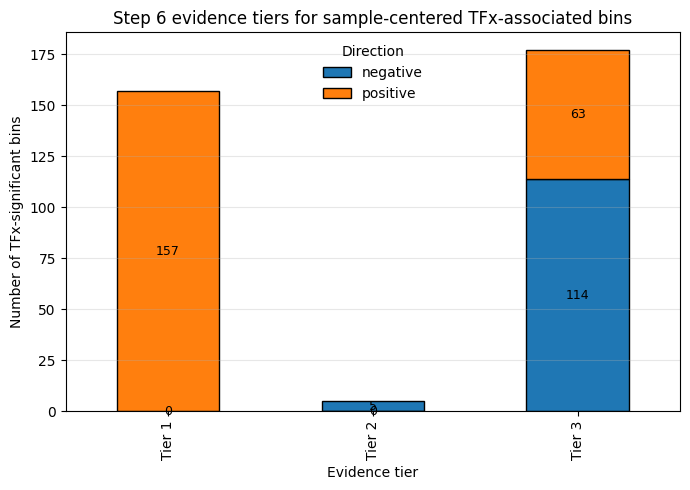


Plotting top prioritized regions by direction


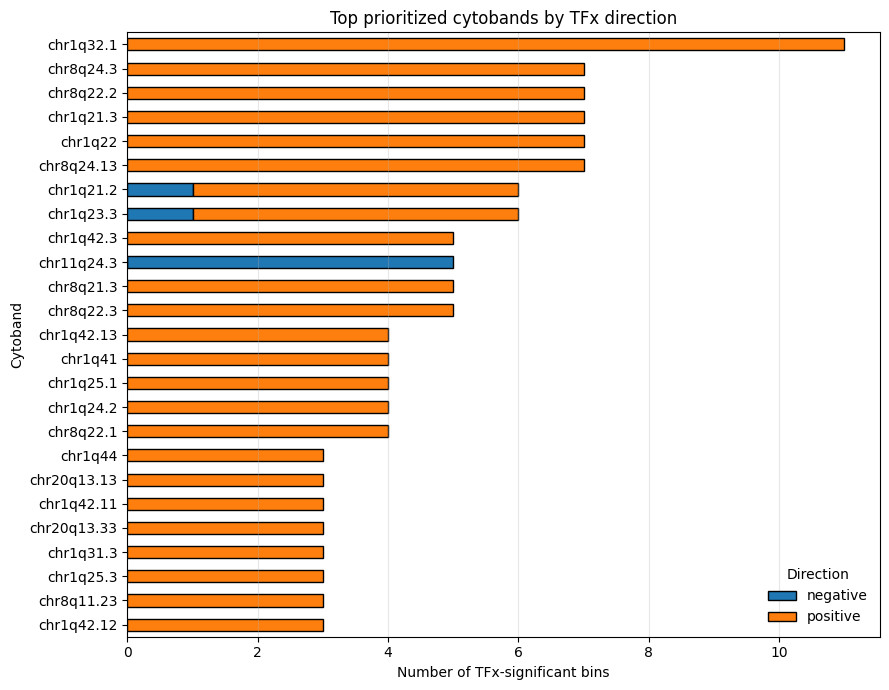


Plotting chr1q/chr8q/chr20q candidate-region summary


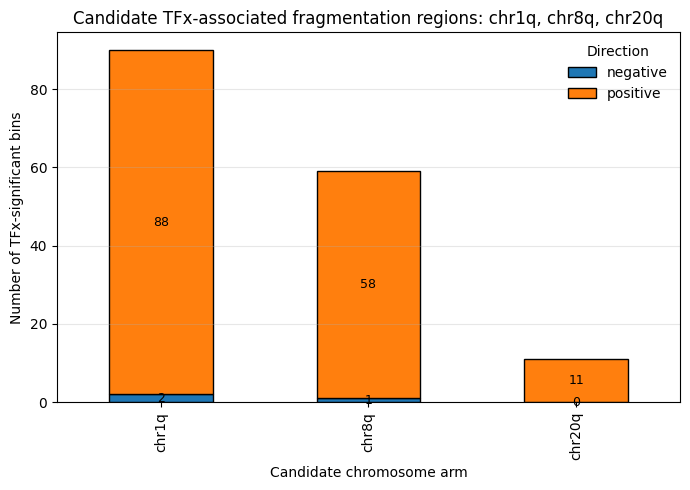


Plotting evidence-layer dotplot


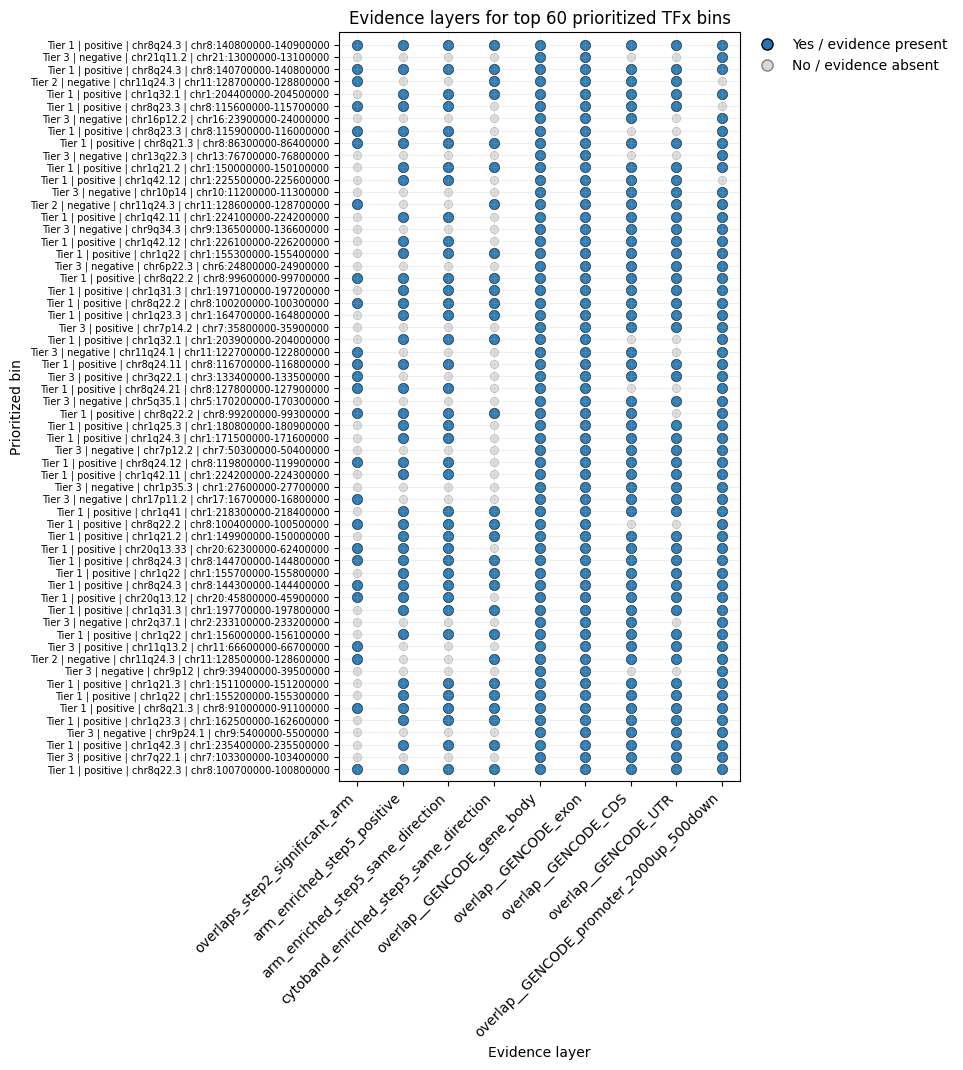

In [125]:
# ## 11. Plots

# 11A. Evidence tier barplot

print_section("Plotting evidence tier barplot")

tier_plot = pd.crosstab(
    master_out["evidence_tier"],
    master_out["direction"]
).reindex(["Tier 1", "Tier 2", "Tier 3"])

ax = tier_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5),
    edgecolor="black",
)

ax.set_xlabel("Evidence tier")
ax.set_ylabel("Number of TFx-significant bins")
ax.set_title("Step 6 evidence tiers for sample-centered TFx-associated bins")
ax.legend(title="Direction", frameon=False)
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, label_type="center", fontsize=9)

save_plot(STEP6_PLOT_DIR / "06_evidence_tier_barplot.png")


# 11B. Top prioritized cytobands by direction

print_section("Plotting top prioritized regions by direction")

plot_regions = cytoband_summary.copy()
plot_regions = plot_regions[plot_regions["cytoband_full"].notna()].copy()

plot_regions["region_total_score"] = (
    plot_regions["n_tier1"] * 3
    + plot_regions["n_tier2"] * 2
    + plot_regions["n_bins"]
)

top_regions = (
    plot_regions
    .groupby("cytoband_full", dropna=False)
    .agg(region_total_score=("region_total_score", "sum"), n_bins=("n_bins", "sum"))
    .reset_index()
    .sort_values(["region_total_score", "n_bins"], ascending=[False, False])
    .head(TOP_N_REGIONS_TO_PLOT)["cytoband_full"]
)

region_direction_counts = (
    master_out[master_out["cytoband_full"].isin(top_regions)]
    .groupby(["cytoband_full", "direction"])
    .size()
    .unstack(fill_value=0)
)

region_direction_counts["total"] = region_direction_counts.sum(axis=1)
region_direction_counts = region_direction_counts.sort_values("total", ascending=True)
region_direction_counts = region_direction_counts.drop(columns="total")

ax = region_direction_counts.plot(
    kind="barh",
    stacked=True,
    figsize=(9, max(5, 0.28 * region_direction_counts.shape[0])),
    edgecolor="black",
)

ax.set_xlabel("Number of TFx-significant bins")
ax.set_ylabel("Cytoband")
ax.set_title("Top prioritized cytobands by TFx direction")
ax.legend(title="Direction", frameon=False)
ax.grid(axis="x", alpha=0.3)

save_plot(STEP6_PLOT_DIR / "06_top_prioritized_cytobands_by_direction.png")

# 11C. chr1q / chr8q / chr20q candidate-region summary

print_section("Plotting chr1q/chr8q/chr20q candidate-region summary")

candidate_plot = (
    master_out[master_out["chrom_arm"].isin(["chr1q", "chr8q", "chr20q"])]
    .groupby(["chrom_arm", "direction"])
    .size()
    .unstack(fill_value=0)
    .reindex(["chr1q", "chr8q", "chr20q"])
)

ax = candidate_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5),
    edgecolor="black",
)

ax.set_xlabel("Candidate chromosome arm")
ax.set_ylabel("Number of TFx-significant bins")
ax.set_title("Candidate TFx-associated fragmentation regions: chr1q, chr8q, chr20q")
ax.legend(title="Direction", frameon=False)
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, label_type="center", fontsize=9)

save_plot(STEP6_PLOT_DIR / "06_chr1q_chr8q_chr20q_candidate_region_summary.png")


# 11D. Evidence-layer heatmap/dotplot for top prioritized bins

print_section("Plotting evidence-layer dotplot")

dot_cols = [
    "overlaps_step2_significant_arm",
    "arm_enriched_step5_positive",
    "arm_enriched_step5_same_direction",
    "cytoband_enriched_step5_same_direction",
    "overlap__GENCODE_gene_body",
    "overlap__GENCODE_exon",
    "overlap__GENCODE_CDS",
    "overlap__GENCODE_UTR",
    "overlap__GENCODE_promoter_2000up_500down",
]

dot_cols = [c for c in dot_cols if c in master_out.columns]

dot_df = master_out.head(60).copy()

dot_df["bin_label"] = (
    dot_df["evidence_tier"].astype(str)
    + " | "
    + dot_df["direction"].astype(str)
    + " | "
    + dot_df["cytoband_full"].astype(str)
    + " | "
    + dot_df["bin_id"].astype(str)
)

plot_matrix = dot_df[dot_cols].astype(bool).astype(int)

fig, ax = plt.subplots(
    figsize=(12, max(7, 0.18 * dot_df.shape[0]))
)

for y_i, (_, row) in enumerate(plot_matrix.iterrows()):
    for x_i, col in enumerate(dot_cols):

        if row[col] == 1:
            ax.scatter(
                x_i,
                y_i,
                s=55,
                color="#1f77b4",   # Yes / evidence present
                edgecolor="black",
                linewidth=0.4,
                alpha=0.95,
            )
        else:
            ax.scatter(
                x_i,
                y_i,
                s=35,
                color="#d9d9d9",   # No / evidence absent
                edgecolor="gray",
                linewidth=0.3,
                alpha=0.8,
            )

ax.set_xticks(range(len(dot_cols)))
ax.set_xticklabels(dot_cols, rotation=45, ha="right")

ax.set_yticks(range(dot_df.shape[0]))
ax.set_yticklabels(dot_df["bin_label"], fontsize=7)

ax.set_ylim(-1, dot_df.shape[0])
ax.invert_yaxis()

ax.set_title("Evidence layers for top 60 prioritized TFx bins")
ax.set_xlabel("Evidence layer")
ax.set_ylabel("Prioritized bin")

ax.grid(alpha=0.2)

# legend
yes_dot = plt.Line2D(
    [0], [0],
    marker="o",
    color="w",
    label="Yes / evidence present",
    markerfacecolor="#1f77b4",
    markeredgecolor="black",
    markersize=8,
)

no_dot = plt.Line2D(
    [0], [0],
    marker="o",
    color="w",
    label="No / evidence absent",
    markerfacecolor="#d9d9d9",
    markeredgecolor="gray",
    markersize=8,
)

# Put legend outside the plotting area on the right
legend = ax.legend(
    handles=[yes_dot, no_dot],
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0,
)

# Leave extra space on right side for the legend
plt.tight_layout(rect=[0, 0, 0.82, 1])

plt.savefig(
    STEP6_PLOT_DIR / "06_top_prioritized_bins_evidence_layer_dotplot.png",
    dpi=300,
    bbox_inches="tight",
    bbox_extra_artists=[legend],
)

plt.savefig(
    STEP6_PLOT_DIR / "06_top_prioritized_bins_evidence_layer_dotplot.pdf",
    bbox_inches="tight",
    bbox_extra_artists=[legend],
)

plt.show()


In [126]:
# 11. Filter prioritized genes for protein-coding curated cancer genes

print_section("Filtering prioritized-bin genes for protein-coding curated cancer genes")

# ------------------------------------------------------------
# Input files
# ------------------------------------------------------------

CANCER_GENE_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/cancerGeneList.tsv"
)

gene_long_file = STEP6_TABLE_DIR / "06_prioritized_bins_gene_level_long_table.tsv"

print("Gene-bin long table:")
print(gene_long_file)

print("\nCurated cancer gene list:")
print(CANCER_GENE_FILE)


# ------------------------------------------------------------
# Load prioritized bin-to-gene table
# ------------------------------------------------------------

if "gene_bin_table" in globals() and isinstance(gene_bin_table, pd.DataFrame):
    prioritized_gene_bins = gene_bin_table.copy()
else:
    prioritized_gene_bins = pd.read_csv(gene_long_file, sep="\t")

print("\nPrioritized gene-bin table:")
print(prioritized_gene_bins.shape)
display(prioritized_gene_bins.head())


# ------------------------------------------------------------
# Load curated cancer gene list
# ------------------------------------------------------------

cancer_genes_df = pd.read_csv(CANCER_GENE_FILE, sep="\t")

cancer_genes_df["Hugo Symbol"] = (
    cancer_genes_df["Hugo Symbol"]
    .astype(str)
    .str.strip()
)

cancer_genes_df["cancer_gene_upper"] = (
    cancer_genes_df["Hugo Symbol"]
    .astype(str)
    .str.strip()
    .str.upper()
)

cancer_gene_set = set(
    cancer_genes_df["cancer_gene_upper"]
    .dropna()
    .astype(str)
)

print("\nCancer gene list:")
print(cancer_genes_df.shape)
print("Unique curated cancer genes:", len(cancer_gene_set))

display(cancer_genes_df.head())


# ------------------------------------------------------------
# Build GENCODE gene-type lookup
# ------------------------------------------------------------
# Requires gencode_genes from the previous GTF parsing/gene-annotation block.

if "gencode_genes" not in globals():
    raise ValueError(
        "gencode_genes object not found. "
        "Rerun the GENCODE gene parsing block before this section."
    )

gencode_gene_type_lookup = (
    gencode_genes[["gene_name", "gene_id", "gene_type"]]
    .drop_duplicates()
    .copy()
)

gencode_gene_type_lookup["gene_upper"] = (
    gencode_gene_type_lookup["gene_name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

gencode_gene_type_lookup = (
    gencode_gene_type_lookup
    .groupby("gene_upper", as_index=False)
    .agg(
        gencode_gene_name=("gene_name", lambda x: ";".join(sorted(set(x.astype(str))))),
        gencode_gene_id=("gene_id", lambda x: ";".join(sorted(set(x.astype(str))))),
        gencode_gene_type=("gene_type", lambda x: ";".join(sorted(set(x.astype(str)))))
    )
)

print("\nGENCODE gene-type lookup:")
print(gencode_gene_type_lookup.shape)
display(gencode_gene_type_lookup.head())


# ------------------------------------------------------------
# Add GENCODE gene type and curated cancer-gene flag
# ------------------------------------------------------------

prioritized_gene_bins_annot = prioritized_gene_bins.copy()

prioritized_gene_bins_annot["gene_upper"] = (
    prioritized_gene_bins_annot["gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

prioritized_gene_bins_annot = prioritized_gene_bins_annot.merge(
    gencode_gene_type_lookup,
    on="gene_upper",
    how="left"
)

prioritized_gene_bins_annot = prioritized_gene_bins_annot.merge(
    cancer_genes_df,
    left_on="gene_upper",
    right_on="cancer_gene_upper",
    how="left"
)

prioritized_gene_bins_annot["is_protein_coding"] = (
    prioritized_gene_bins_annot["gencode_gene_type"]
    .fillna("")
    .astype(str)
    .str.split(";")
    .apply(lambda x: "protein_coding" in x)
)

prioritized_gene_bins_annot["is_curated_cancer_gene"] = (
    prioritized_gene_bins_annot["gene_upper"].isin(cancer_gene_set)
)

prioritized_gene_bins_annot["is_protein_coding_curated_cancer_gene"] = (
    prioritized_gene_bins_annot["is_protein_coding"]
    & prioritized_gene_bins_annot["is_curated_cancer_gene"]
)

print("\nAnnotation summary:")
print("Total gene-bin rows:", prioritized_gene_bins_annot.shape[0])
print("Protein-coding rows:", prioritized_gene_bins_annot["is_protein_coding"].sum())
print("Curated cancer-gene rows:", prioritized_gene_bins_annot["is_curated_cancer_gene"].sum())
print(
    "Protein-coding curated cancer-gene rows:",
    prioritized_gene_bins_annot["is_protein_coding_curated_cancer_gene"].sum()
)


# ------------------------------------------------------------
# Filter to protein-coding curated cancer genes
# ------------------------------------------------------------

protein_coding_curated_cancer_gene_bins = prioritized_gene_bins_annot[
    prioritized_gene_bins_annot["is_protein_coding_curated_cancer_gene"]
].copy()

protein_coding_curated_cancer_gene_bins_overlap_only = (
    protein_coding_curated_cancer_gene_bins[
        protein_coding_curated_cancer_gene_bins["gene_source"].eq("overlapping")
    ].copy()
)

print("\nProtein-coding curated cancer-gene rows:")
print(protein_coding_curated_cancer_gene_bins.shape)

print("\nProtein-coding curated cancer-gene direct-overlap rows:")
print(protein_coding_curated_cancer_gene_bins_overlap_only.shape)

display_cols = [
    "gene",
    "gene_source",
    "bin_id",
    "direction",
    "evidence_tier",
    "chrom_arm",
    "cytoband_full",
    "tfx_coef",
    "abs_tfx_coef",
    "tfx_qvalue",
    "priority_score",
    "gencode_gene_type",
    "Gene Type",
    "# of occurrence within resources (Column K-P)",
    "OncoKB Annotated",
    "MSK-IMPACT",
    "FOUNDATION ONE",
    "Vogelstein",
    "COSMIC CGC (v99)",
]

display_cols = [
    c for c in display_cols
    if c in protein_coding_curated_cancer_gene_bins_overlap_only.columns
]

display(protein_coding_curated_cancer_gene_bins_overlap_only[display_cols].head(30))


# ------------------------------------------------------------
# Summarize protein-coding curated cancer genes
# ------------------------------------------------------------

summary_group_cols = [
    "gene",
    "Gene Type",
    "# of occurrence within resources (Column K-P)",
    "OncoKB Annotated",
    "MSK-IMPACT",
    "FOUNDATION ONE",
    "Vogelstein",
    "COSMIC CGC (v99)",
]

summary_group_cols = [
    c for c in summary_group_cols
    if c in protein_coding_curated_cancer_gene_bins_overlap_only.columns
]

if protein_coding_curated_cancer_gene_bins_overlap_only.shape[0] > 0:
    protein_coding_curated_cancer_gene_summary = (
        protein_coding_curated_cancer_gene_bins_overlap_only
        .groupby(summary_group_cols, dropna=False)
        .agg(
            n_bins=("bin_id", "nunique"),
            directions=("direction", lambda x: ";".join(sorted(set(x.astype(str))))),
            tiers=("evidence_tier", lambda x: ";".join(sorted(set(x.astype(str))))),
            arms=("chrom_arm", lambda x: ";".join(sorted(set(x.dropna().astype(str))))),
            cytobands=("cytoband_full", lambda x: ";".join(sorted(set(x.dropna().astype(str))))),
            median_abs_tfx_coef=("abs_tfx_coef", "median"),
            min_tfx_qvalue=("tfx_qvalue", "min"),
            max_priority_score=("priority_score", "max"),
        )
        .reset_index()
        .sort_values(
            ["n_bins", "max_priority_score", "median_abs_tfx_coef"],
            ascending=[False, False, False],
        )
    )
else:
    protein_coding_curated_cancer_gene_summary = pd.DataFrame()

print("\nProtein-coding curated cancer-gene summary:")
print(protein_coding_curated_cancer_gene_summary.shape)

display(protein_coding_curated_cancer_gene_summary.head(30))


# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------

prioritized_gene_bins_annot.to_csv(
    STEP6_TABLE_DIR / "06_prioritized_bins_all_genes_with_gencode_and_cancer_annotation.tsv",
    sep="\t",
    index=False,
)

protein_coding_curated_cancer_gene_bins.to_csv(
    STEP6_TABLE_DIR / "06_prioritized_bins_protein_coding_curated_cancer_genes.tsv",
    sep="\t",
    index=False,
)

protein_coding_curated_cancer_gene_bins_overlap_only.to_csv(
    STEP6_TABLE_DIR / "06_prioritized_bins_protein_coding_curated_cancer_genes_OVERLAP_ONLY.tsv",
    sep="\t",
    index=False,
)

protein_coding_curated_cancer_gene_summary.to_csv(
    STEP6_TABLE_DIR / "06_top_protein_coding_curated_cancer_genes_near_prioritized_bins.tsv",
    sep="\t",
    index=False,
)

print("\nSaved:")
print(STEP6_TABLE_DIR / "06_prioritized_bins_all_genes_with_gencode_and_cancer_annotation.tsv")
print(STEP6_TABLE_DIR / "06_prioritized_bins_protein_coding_curated_cancer_genes.tsv")
print(STEP6_TABLE_DIR / "06_prioritized_bins_protein_coding_curated_cancer_genes_OVERLAP_ONLY.tsv")
print(STEP6_TABLE_DIR / "06_top_protein_coding_curated_cancer_genes_near_prioritized_bins.tsv")


Filtering prioritized-bin genes for protein-coding curated cancer genes
Gene-bin long table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_prioritized_bins_gene_level_long_table.tsv

Curated cancer gene list:
/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/cancerGeneList.tsv

Prioritized gene-bin table:
(898, 12)


,gene,gene_source,bin_id,direction,evidence_tier,chrom_arm,cytoband_full,tfx_coef,abs_tfx_coef,tfx_qvalue,priority_score,nearest_gene_distance_bp
0,ENSG00000279786,overlapping,chr8:140800000-140900000,positive,Tier 1,chr8q,chr8q24.3,0.001634,0.001634,1.066679e-08,6.325474,0.0
1,PTK2,overlapping,chr8:140800000-140900000,positive,Tier 1,chr8q,chr8q24.3,0.001634,0.001634,1.066679e-08,6.325474,0.0
2,MIR151A,overlapping,chr8:140700000-140800000,positive,Tier 1,chr8q,chr8q24.3,0.001292,0.001292,4.510438e-05,5.852052,0.0
3,PTK2,overlapping,chr8:140700000-140800000,positive,Tier 1,chr8q,chr8q24.3,0.001292,0.001292,4.510438e-05,5.852052,0.0
4,FLI1,overlapping,chr11:128700000-128800000,negative,Tier 2,chr11q,chr11q24.3,-0.001478,0.001478,4.510438e-05,3.912391,0.0



Cancer gene list:
(1236, 17)
Unique curated cancer genes: 1236


,Hugo Symbol,Entrez Gene ID,GRCh37 Isoform,GRCh37 RefSeq,GRCh38 Isoform,GRCh38 RefSeq,Gene Type,# of occurrence within resources (Column K-P),OncoKB Annotated,MSK-IMPACT,MSK-HEME,FOUNDATION ONE,FOUNDATION ONE HEME,Vogelstein,COSMIC CGC (v99),Gene Aliases,cancer_gene_upper
0,ABL1,25,ENST00000318560,NM_005157.4,ENST00000318560,NM_005157.4,ONCOGENE,7,Yes,Yes,Yes,Yes,Yes,Yes,Yes,"ABL, JTK7, c-ABL",ABL1
1,AKT1,207,ENST00000349310,NM_001014431.1,ENST00000349310,NM_001014431.1,ONCOGENE,7,Yes,Yes,Yes,Yes,Yes,Yes,Yes,"AKT, PKB, PRKBA, RAC, RAC-alpha",AKT1
2,ALK,238,ENST00000389048,NM_004304.4,ENST00000389048,NM_004304.4,ONCOGENE,7,Yes,Yes,Yes,Yes,Yes,Yes,Yes,CD246,ALK
3,AMER1,139285,ENST00000330258,NM_152424.3,ENST00000374869,NM_152424.3,TSG,7,Yes,Yes,Yes,Yes,Yes,Yes,Yes,"FAM123B, FLJ39827, RP11-403E24.2, WTX",AMER1
4,APC,324,ENST00000257430,NM_000038.5,ENST00000257430,NM_000038.5,TSG,7,Yes,Yes,Yes,Yes,Yes,Yes,Yes,"DP2.5, PPP1R46",APC



GENCODE gene-type lookup:
(77114, 4)


...


Annotation summary:
Total gene-bin rows: 898
Protein-coding rows: 378
Curated cancer-gene rows: 37
Protein-coding curated cancer-gene rows: 37

Protein-coding curated cancer-gene rows:
(37, 36)

Protein-coding curated cancer-gene direct-overlap rows:
(37, 36)


,gene,gene_source,bin_id,direction,evidence_tier,chrom_arm,cytoband_full,tfx_coef,abs_tfx_coef,tfx_qvalue,priority_score,gencode_gene_type,Gene Type,# of occurrence within resources (Column K-P),OncoKB Annotated,MSK-IMPACT,FOUNDATION ONE,Vogelstein,COSMIC CGC (v99)
4,FLI1,overlapping,chr11:128700000-128800000,negative,Tier 2,chr11q,chr11q24.3,-0.001478,0.001478,0.000045,3.912391,protein_coding,ONCOGENE,3.0,Yes,No,No,No,Yes
6,PIK3C2B,overlapping,chr1:204400000-204500000,positive,Tier 1,chr1q,chr1q32.1,0.001165,0.001165,0.000058,5.800308,protein_coding,ONCOGENE,2.0,Yes,No,Yes,No,No
13,WWP1,overlapping,chr8:86300000-86400000,positive,Tier 1,chr8q,chr8q21.3,0.001508,0.001508,0.000106,5.885150,protein_coding,ONCOGENE,1.0,Yes,No,No,No,No
23,FLI1,overlapping,chr11:128600000-128700000,negative,Tier 2,chr11q,chr11q24.3,-0.001108,0.001108,0.000148,3.741170,protein_coding,ONCOGENE,3.0,Yes,No,No,No,Yes
57,PBX1,overlapping,chr1:164700000-164800000,positive,Tier 1,chr1q,chr1q23.3,0.001423,0.001423,0.000393,5.800382,protein_coding,NaN,2.0,No,No,No,No,Yes
168,LMNA,overlapping,chr1:156000000-156100000,positive,Tier 1,chr1q,chr1q22,0.000972,0.000972,0.002138,5.581156,protein_coding,ONCOGENE,2.0,Yes,No,No,No,Yes
175,ETS1,overlapping,chr11:128500000-128600000,negative,Tier 2,chr11q,chr11q24.3,-0.001007,0.001007,0.002293,3.589326,protein_coding,ONCOGENE_AND_TSG,2.0,Yes,No,No,No,No
240,COP1,overlapping,chr1:175900000-176000000,positive,Tier 1,chr1q,chr1q25.1,0.000945,0.000945,0.002851,5.560047,protein_coding,ONCOGENE_AND_TSG,3.0,Yes,Yes,No,No,No
253,SMYD3,overlapping,chr1:246500000-246600000,positive,Tier 1,chr1q,chr1q44,0.001100,0.001100,0.002851,5.610146,protein_coding,ONCOGENE,3.0,Yes,Yes,No,No,No
267,TPR,overlapping,chr1:186300000-186400000,positive,Tier 1,chr1q,chr1q31.1,0.001252,0.001252,0.002997,5.657048,protein_coding,NaN,1.0,No,No,No,No,Yes



Protein-coding curated cancer-gene summary:
(29, 16)


,gene,Gene Type,# of occurrence within resources (Column K-P),OncoKB Annotated,MSK-IMPACT,FOUNDATION ONE,Vogelstein,COSMIC CGC (v99),n_bins,directions,tiers,arms,cytobands,median_abs_tfx_coef,min_tfx_qvalue,max_priority_score
4,ARID4B,TSG,2.0,Yes,No,No,No,No,3,positive,Tier 1,chr1q,chr1q42.3,0.000802,0.009563,5.538774
10,FLI1,ONCOGENE,3.0,Yes,No,No,No,Yes,3,negative,Tier 2,chr11q,chr11q24.3,0.001108,0.000045,3.912391
28,WWP1,ONCOGENE,1.0,Yes,No,No,No,No,2,positive,Tier 1,chr8q,chr8q21.3,0.001316,0.000106,5.885150
24,SMYD3,ONCOGENE,3.0,Yes,Yes,No,No,No,2,positive,Tier 1,chr1q,chr1q44,0.000888,0.002851,5.610146
9,EXT1,TSG,2.0,Yes,No,No,No,Yes,2,positive,Tier 1,chr8q,chr8q24.11,0.000850,0.025695,5.439967
8,ETS1,ONCOGENE_AND_TSG,2.0,Yes,No,No,No,No,2,negative,Tier 2,chr11q,chr11q24.3,0.001016,0.002293,3.589326
19,PBX1,NaN,2.0,No,No,No,No,Yes,1,positive,Tier 1,chr1q,chr1q23.3,0.001423,0.000393,5.800382
20,PIK3C2B,ONCOGENE,2.0,Yes,No,Yes,No,No,1,positive,Tier 1,chr1q,chr1q32.1,0.001165,0.000058,5.800308
26,TPR,NaN,1.0,No,No,No,No,Yes,1,positive,Tier 1,chr1q,chr1q31.1,0.001252,0.002997,5.657048
18,NCOA2,NaN,2.0,No,No,No,No,Yes,1,positive,Tier 1,chr8q,chr8q13.3,0.001320,0.019150,5.598414



Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_prioritized_bins_all_genes_with_gencode_and_cancer_annotation.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_prioritized_bins_protein_coding_curated_cancer_genes.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_prioritized_bins_protein_coding_curated_cancer_genes_OVERLAP_ONLY.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_top_protein_coding_curated_cancer_genes_near_prioritized_bins.tsv


In [127]:
# 13. Write interpretation notes

print_section("Writing Step 6 interpretation notes")

notes_file = STEP6_TABLE_DIR / "06_step6_scientific_notes.txt"

# ------------------------------------------------------------
# summaries
# ------------------------------------------------------------

n_total_bins = master_out.shape[0]

n_positive = int((master_out["direction"] == "positive").sum())
n_negative = int((master_out["direction"] == "negative").sum())

tier_counts = (
    master_out["evidence_tier"]
    .value_counts()
    .to_dict()
)

tier1_n = int(tier_counts.get("Tier 1", 0))
tier2_n = int(tier_counts.get("Tier 2", 0))
tier3_n = int(tier_counts.get("Tier 3", 0))

tier_direction_summary = (
    master_out
    .groupby(["evidence_tier", "direction"])
    .size()
    .reset_index(name="n_bins")
    .sort_values(["evidence_tier", "direction"])
)

# Positive enriched arms
if "positive_enriched_arms" in globals():
    positive_arm_text = ", ".join(sorted(positive_enriched_arms))
else:
    positive_arm_text = "not available"

# Negative enriched arms
if "negative_enriched_arms" in globals():
    if len(negative_enriched_arms) > 0:
        negative_arm_text = ", ".join(sorted(negative_enriched_arms))
    else:
        negative_arm_text = "none"
else:
    negative_arm_text = "not available"

# Cancer gene summary
if (
    "protein_coding_curated_cancer_gene_bins_overlap_only" in globals()
    and isinstance(protein_coding_curated_cancer_gene_bins_overlap_only, pd.DataFrame)
):
    n_pc_cancer_overlap_rows = protein_coding_curated_cancer_gene_bins_overlap_only.shape[0]
    n_pc_cancer_overlap_bins = protein_coding_curated_cancer_gene_bins_overlap_only["bin_id"].nunique()
    n_pc_cancer_overlap_genes = protein_coding_curated_cancer_gene_bins_overlap_only["gene"].nunique()
else:
    n_pc_cancer_overlap_rows = 0
    n_pc_cancer_overlap_bins = 0
    n_pc_cancer_overlap_genes = 0

if (
    "protein_coding_curated_cancer_gene_summary" in globals()
    and isinstance(protein_coding_curated_cancer_gene_summary, pd.DataFrame)
    and protein_coding_curated_cancer_gene_summary.shape[0] > 0
):
    top_cancer_gene_text = ", ".join(
        protein_coding_curated_cancer_gene_summary["gene"]
        .head(10)
        .astype(str)
        .tolist()
    )
else:
    top_cancer_gene_text = "none detected among direct-overlap prioritized bins"


# ------------------------------------------------------------
# Write notes
# ------------------------------------------------------------

notes = f"""
Step 6 scientific interpretation notes
======================================

Goal
----
Step 6 prioritizes and annotates the 339 sample-centered tumor-fraction-associated
regional fragmentation bins identified in Step 3. These bins were significant for
the tumor-fraction term after modeling regional fragmentation as a function of
treatment context and tumor fraction, with patient-level clustering handled upstream.

Important data consistency check
--------------------------------
The Step 3 tumor-fraction statistics were filtered to matrix_type == "sample_centered"
before merging into the Step 6 master table. This is necessary because the Step 3
significant-bin file also contains raw-matrix results. After filtering, the Step 3
coefficient direction matched the Step 4 BED direction labels.

Bin summary
-----------
Total TFx-associated sample-centered bins: {n_total_bins}
Positive TFx-associated bins: {n_positive}
Negative TFx-associated bins: {n_negative}

Evidence-tier summary
---------------------
Tier 1 bins: {tier1_n}
Tier 2 bins: {tier2_n}
Tier 3 bins: {tier3_n}

Tier definitions
----------------
Tier 1 bins are positive TFx-associated bins located in FDR-significant
positive-enriched chromosome arms from Step 5. In this analysis, the positive
arm-enrichment signal includes: {positive_arm_text}.

Tier 2 bins are TFx-associated bins supported by focal direction-specific cytoband
enrichment but not assigned to Tier 1.

Tier 3 bins are TFx-significant bins without chromosome-arm or focal cytoband
enrichment support.

Direction-specific interpretation
---------------------------------
The chromosome-arm enrichment signal is primarily driven by positive TFx-associated
bins. No negative chromosome arm passed the same direction-specific FDR enrichment
criterion in Step 5: {negative_arm_text}.

Positive bins should be interpreted as regions where the sample-centered regional
short/long fragmentation signal increases with tumor fraction. Negative bins should
be interpreted as regions where the sample-centered regional short/long fragmentation
signal decreases with tumor fraction.

Cancer-gene annotation
----------------------
Prioritized bins were further annotated using GENCODE gene coordinates and a curated
cancer gene list. Direct-overlap filtering identified:

Protein-coding curated cancer-gene overlap rows: {n_pc_cancer_overlap_rows}
Unique prioritized bins overlapping protein-coding curated cancer genes: {n_pc_cancer_overlap_bins}
Unique protein-coding curated cancer genes overlapped by prioritized bins: {n_pc_cancer_overlap_genes}

Top protein-coding curated cancer genes by prioritized-bin overlap:
{top_cancer_gene_text}

Interpretation limits
---------------------
These are regional fragmentation-associated bins, not direct copy-number alteration,
mutation, amplification, deletion, or expression calls.

A bin overlapping a gene means that the genomic interval of the fragmentation signal
overlaps or is near that gene annotation. It does not mean that the gene itself is
mutated, amplified, deleted, differentially expressed, or causally driving the
fragmentation signal.

Positive bins on enriched arms such as chr1q, chr8q, and chr20q should therefore be
described as tumor-fraction-associated regional fragmentation enrichment on these
arms, not as direct evidence of arm-level amplification in every sample.

Recommended downstream use
--------------------------
The prioritized Tier 1/Tier 2 bins and the protein-coding curated cancer-gene-overlap
subset can be used to define candidate regional fragmentation signatures. These
signatures should next be converted into sample-level scores and tested against
tumor fraction, treatment context, and clinical variables.
"""

with open(notes_file, "w") as f:
    f.write(notes)

print("Saved Step 6 interpretation notes:")
print(notes_file)

print(notes)
print("Saved interpretation notes:")
print(notes_path)




Writing Step 6 interpretation notes
Saved Step 6 interpretation notes:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step6_prioritization_tables/06_step6_scientific_notes.txt

Step 6 scientific interpretation notes

Goal
----
Step 6 prioritizes and annotates the 339 sample-centered tumor-fraction-associated
regional fragmentation bins identified in Step 3. These bins were significant for
the tumor-fraction term after modeling regional fragmentation as a function of
treatment context and tumor fraction, with patient-level clustering handled upstream.

Important data consistency check
--------------------------------
The Step 3 tumor-fraction statistics were filtered to matrix_type == "sample_centered"
before merging into the Step 6 master table. This is necessary because the Step 3
significant-bin file also contains raw-matrix results. After filtering, the Step 3
coefficient direction matched the Step 4 BED direction label